In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys

sys.path.append("../..")

import json
from pathlib import Path
import numpy as np
import xarray as xr
import regionmask

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid", {"grid.color": ".93"})

from src.data_processing.load_data import ClimateModelData, ClimateReanalysisData

from src.utils.utils_load_data import (
    get_raw_cordex_data_paths,
)

from src.data_processing.convert_climate_vars import (
    convert_wind_components_to_speed,
)

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/bias_correction_2024/share/proj failed


In [3]:
paths = json.load(open("../../paths_so4.json"))

path_data_analysis = Path(paths["path_data_analysis"])
path_data_processed = Path(paths["path_data_processed"])
path_data_cordex = Path(paths["path_data_cordex"])
path_data_adjusted_cordex = Path(paths["path_data_adjusted_cordex"])
path_data_cerra = Path(paths["path_data_cerra"])
path_data_cerra_land = Path(paths["path_data_cerra_land"])
path_data_personal = Path(paths["path_data_personal"])
path_data_personal_cordex = path_data_personal / "cordex"
path_figs = Path(paths["path_figs"])

In [4]:
climate_model_chain = "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1"
climate_scenario = "rcp85"

institute = climate_model_chain.split("-")[0]
rcm = climate_model_chain.split("_")[0]
gcm = climate_model_chain.split("_")[1]
ensemble = climate_model_chain.split("_")[-1]

In [5]:
extent = {"lat_min": 30, "lat_max": 75, "lon_min": -12, "lon_max": 30}

In [6]:
ds_mrro = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
    / "regridded"
    / "day"
    / "mrro.zarr",
    extent=None,
)
ds_mrro.ds_data

<xarray.Dataset> Size: 795GB
Dimensions:  (lat: 1400, lon: 3600, time: 39420)
Coordinates:
  * lat      (lat) float64 11kB -56.0 -55.9 -55.8 -55.7 ... 83.6 83.7 83.8 83.9
  * lon      (lon) float64 29kB -180.0 -179.9 -179.8 ... 179.7 179.8 179.9
  * time     (time) datetime64[ns] 315kB 1991-01-01T12:00:00 ... 2098-12-31T1...
Data variables:
    mrro     (time, lat, lon) float32 795GB ...
Attributes: (12/29)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Convention:                     CF-1.6
    Conventions:                    CF-1.6
    c3s_disclaimer:                 This data has been produced in the contex...
    ...                             ...
    product:                        output
    project_id:                     CORDEX
    rcm_version_id:                 v2
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    title:                          Created by xios
    tracking_id:                    hdl:21.14103/637a71b3-ab2d-4cd7-a5a6-ddc0...

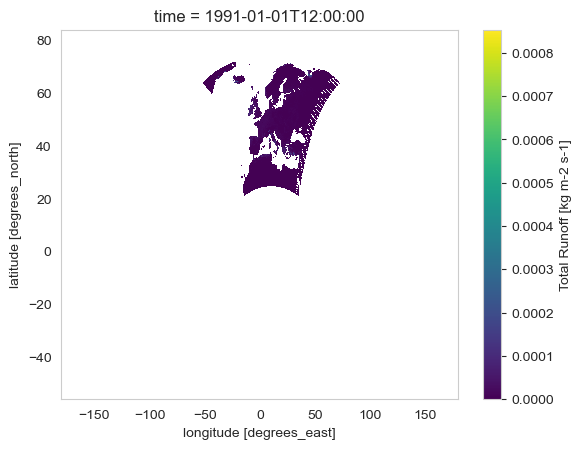

In [12]:
ds_mrro.ds_data.isel(time=0).mrro.plot()

In [ ]:
# Extract the data for the first time step
data = ds_mrro.ds_data.isel(time=0).mrro

# Find the indices where the data is non-zero
non_zero_data = data.where(data > 0, drop=True)

# Detect the extent
lat_min = non_zero_data.lat.min().item()
lat_max = non_zero_data.lat.max().item()
lon_min = non_zero_data.lon.min().item()
lon_max = non_zero_data.lon.max().item()

extent_non_zero = {
    "lat_min": lat_min,
    "lat_max": lat_max,
    "lon_min": lon_min,
    "lon_max": lon_max,
}
extent_non_zero

{'lat_min': 20.89999789585905,
 'lat_max': 71.79999703265003,
 'lon_min': -51.69999912322368,
 'lon_max': 72.69999876708667}

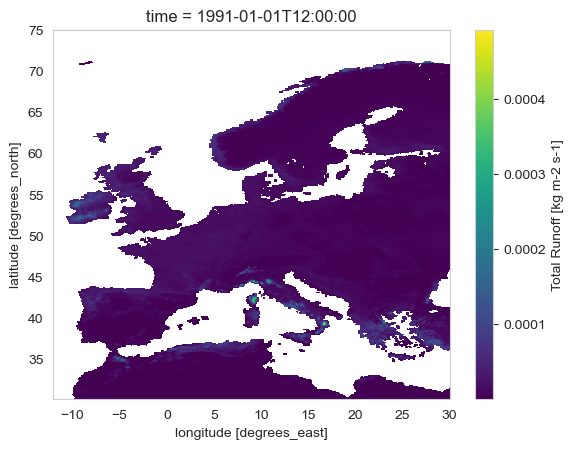

In [7]:
ds_mrro.ds_data.mrro.isel(time=0).plot()

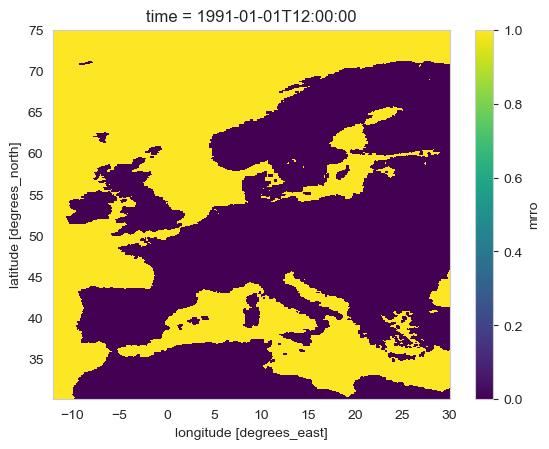

In [8]:
mask_nan = ds_mrro.ds_data.mrro.isel(time=0).isnull()
mask_nan.plot()

In [7]:
ds_mrro_bc = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
    / "bias_corrected"
    / "day"
    / "mrro.zarr",
    chunks={"time": 365, "lat": 256, "lon": 256},
)
ds_mrro_bc.ds_data

<xarray.Dataset> Size: 200GB
Dimensions:  (lat: 510, lon: 1245, time: 39420)
Coordinates:
  * lat      (lat) float64 4kB 20.9 21.0 21.1 21.2 21.3 ... 71.5 71.6 71.7 71.8
    lev      float64 8B ...
  * lon      (lon) float64 10kB -51.7 -51.6 -51.5 -51.4 ... 72.4 72.5 72.6 72.7
  * time     (time) datetime64[ns] 315kB 1991-01-01T12:00:00 ... 2098-12-31T1...
Data variables:
    mrro     (time, lat, lon) float64 200GB dask.array<chunksize=(365, 256, 256), meta=np.ndarray>
Attributes: (12/32)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Convention:                     CF-1.6
    Conventions:                    CF-1.6
    bias_adjustment:                EmpiricalQuantileMapping(group=Grouper(na...
    ...                             ...
    project_id:                     CORDEX
    rcm_version_id:                 v2
    reference_period:               1991 - 2020
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    title:                          Created by xios
    tracking_id:                    hdl:21.14103/637a71b3-ab2d-4cd7-a5a6-ddc0...

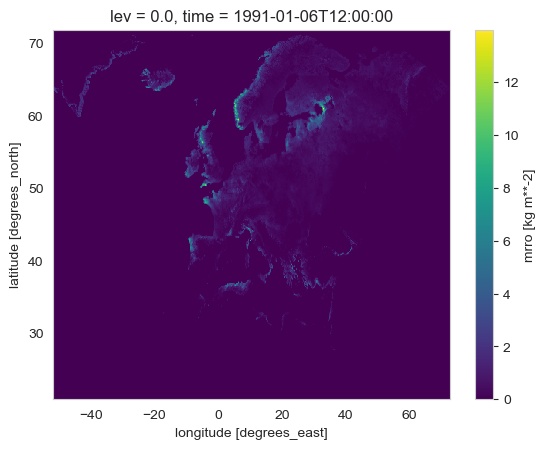

In [12]:
ds_mrro_bc.ds_data.mrro.isel(time=5).plot()

In [6]:
xr.open_zarr(path_data_processed
    / "cordex_processed"
    / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp26"
    / "bias_corrected"
    / "3hr"
    / "tas.zarr")

<xarray.Dataset> Size: 148GB
Dimensions:  (lat: 426, lon: 420, time: 207320)
Coordinates:
  * lat      (lat) float64 3kB 30.05 30.15 30.25 30.35 ... 72.35 72.45 72.55
  * lon      (lon) float64 3kB -11.95 -11.85 -11.75 -11.65 ... 29.75 29.85 29.95
  * time     (time) datetime64[ns] 2MB 1991-01-01 ... 2061-12-31T21:00:00
Data variables:
    tas      (time, lat, lon) float32 148GB dask.array<chunksize=(2920, 128, 128), meta=np.ndarray>
Attributes: (12/32)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Convention:                     CF-1.6
    Conventions:                    CF-1.6
    bias_adjustment:                EmpiricalQuantileMapping(group=Grouper(na...
    ...                             ...
    project_id:                     CORDEX
    rcm_version_id:                 v2
    reference_period:               1991 - 2020
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    title:                          Created by xios
    tracking_id:                    hdl:21.14103/b5f438d4-cd97-40cf-b3d7-6c05...

In [7]:
import pandas as pd
pd.date_range("01-01-1991 00:00", "12-31-2099 00:00", freq="D")

DatetimeIndex(['1991-01-01', '1991-01-02', '1991-01-03', '1991-01-04',
               '1991-01-05', '1991-01-06', '1991-01-07', '1991-01-08',
               '1991-01-09', '1991-01-10',
               ...
               '2099-12-22', '2099-12-23', '2099-12-24', '2099-12-25',
               '2099-12-26', '2099-12-27', '2099-12-28', '2099-12-29',
               '2099-12-30', '2099-12-31'],
              dtype='datetime64[ns]', length=39812, freq='D')

In [5]:
ds_mrro = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
    / "regridded"
    / "day"
    / "mrro.zarr",
    extent={"lat_min": 20.8, "lat_max": 71.8, "lon_min": -51.7, "lon_max": 72.7},
)
ds_mrro.ds_data

<xarray.Dataset> Size: 100GB
Dimensions:  (lat: 510, lon: 1245, time: 39420)
Coordinates:
  * lat      (lat) float64 4kB 20.9 21.0 21.1 21.2 21.3 ... 71.5 71.6 71.7 71.8
  * lon      (lon) float64 10kB -51.7 -51.6 -51.5 -51.4 ... 72.4 72.5 72.6 72.7
  * time     (time) datetime64[ns] 315kB 1991-01-01T12:00:00 ... 2098-12-31T1...
Data variables:
    mrro     (time, lat, lon) float32 100GB ...
Attributes: (12/29)
    CDI:                            Climate Data Interface version 2.4.0 (htt...
    CDO:                            Climate Data Operators version 2.4.0 (htt...
    CORDEX_domain:                  EUR-11
    Convention:                     CF-1.6
    Conventions:                    CF-1.6
    c3s_disclaimer:                 This data has been produced in the contex...
    ...                             ...
    product:                        output
    project_id:                     CORDEX
    rcm_version_id:                 v2
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    title:                          Created by xios
    tracking_id:                    hdl:21.14103/637a71b3-ab2d-4cd7-a5a6-ddc0...

In [ ]:
mask_nan = ds_mrro.ds_data["mrro"].isel(time=0).isnull()
ds_mrro_bc.ds_data.isel(time=0).mrro.where(~mask_nan).plot

<xarray.DataArray 'mrro' (lat: 510, lon: 1245)> Size: 5MB
dask.array<where, shape=(510, 1245), dtype=float64, chunksize=(256, 256), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float64 4kB 20.9 21.0 21.1 21.2 21.3 ... 71.5 71.6 71.7 71.8
    lev      float64 8B ...
  * lon      (lon) float64 10kB -51.7 -51.6 -51.5 -51.4 ... 72.4 72.5 72.6 72.7
    time     datetime64[ns] 8B 1991-01-01T12:00:00
Attributes:
    bias_adjustment:  EmpiricalQuantileMapping(group=Grouper(name='time.dayof...
    history:          [2025-04-02 17:23:33] : Bias-adjusted with EmpiricalQua...
    units:            kg m**-2

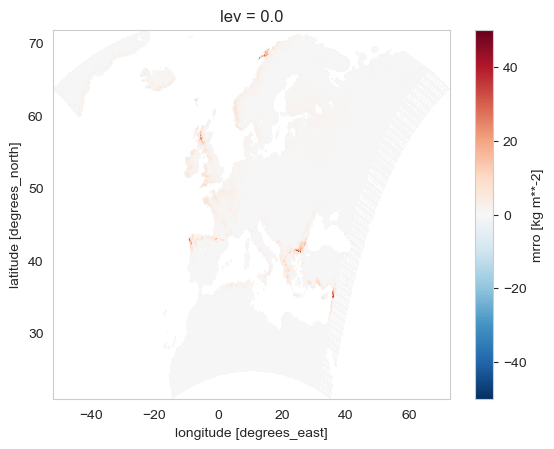

In [41]:
ds_mrro_bc.ds_data.isel(time=10).mrro.where(~mask_nan).plot()

In [9]:
ds_ro_1985 = xr.open_dataset(
    path_data_processed / "cerra_processed" / "ro" / "ro_day_cerra-land_1985.nc"
)
ds_ro_1985

<xarray.Dataset> Size: 2GB
Dimensions:            (time: 365, x: 1069, y: 1069, lev: 1)
Coordinates:
  * time               (time) datetime64[ns] 3kB 1985-01-01 ... 1985-12-31
  * x                  (x) float64 9kB 0.0 5.5e+03 ... 5.868e+06 5.874e+06
  * y                  (y) float64 9kB 0.0 5.5e+03 ... 5.868e+06 5.874e+06
  * lev                (lev) float64 8B 0.0
Data variables:
    Lambert_Conformal  int32 4B ...
    ro                 (time, y, x, lev) float32 2GB ...
Attributes:
    CDI:          Climate Data Interface version 2.4.0 (https://mpimet.mpg.de...
    Conventions:  CF-1.6
    history:      Fri Mar 07 22:09:15 2025: cdo setgrid,/net/exo/landclim/yha...
    CDO:          Climate Data Operators version 2.4.0 (https://mpimet.mpg.de...

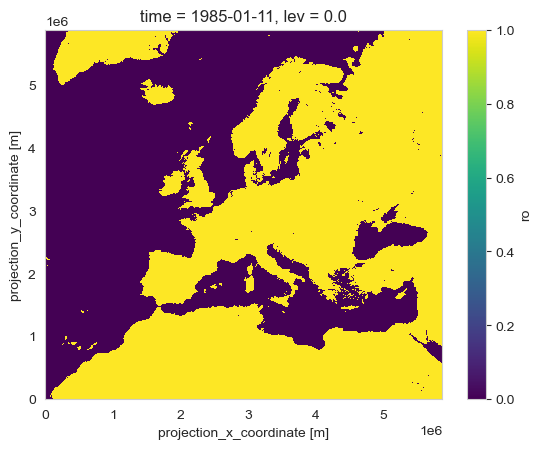

In [48]:
(ds_ro_1985.ro.isel(time=10) > 0).plot()

In [10]:
ds_mrro_2006 = xr.open_dataset(
    "/net/atmos/data/cordex/EUR-11/rcp85/day/mrro/CNRM/CNRM-CERFACS-CNRM-CM5/CNRM-ALADIN63/r1i1p1/mrro_EUR-11_CNRM-CERFACS-CNRM-CM5_rcp85_r1i1p1_CNRM-ALADIN63_v2_day_20060101-20101231.nc"
)

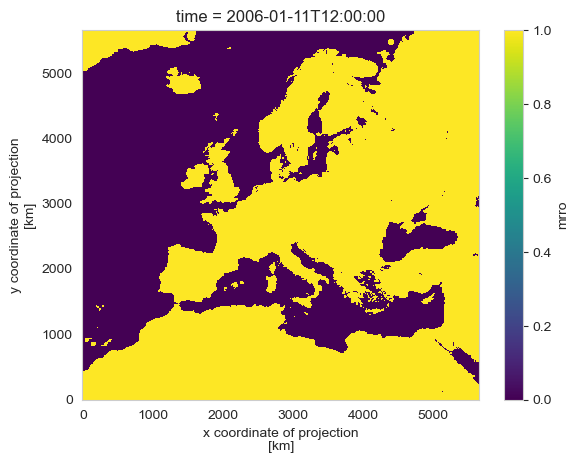

In [51]:
(ds_mrro_2006.mrro.isel(time=10) > 0).plot()

In [11]:
ds_pr = ClimateModelData(
    path_data_processed
    / "cordex_processed"
    / "CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1_rcp85"
    / "regridded"
    / "day"
    / "pr.zarr",
    extent=None,
    chunks="auto",
)
ds_pr.ds_data

<xarray.Dataset> Size: 88GB
Dimensions:  (lat: 507, lon: 1096, time: 39785)
Coordinates:
  * lat      (lat) float64 4kB 21.95 22.05 22.15 22.25 ... 72.35 72.45 72.55
  * lon      (lon) float64 9kB -44.55 -44.45 -44.35 -44.25 ... 64.75 64.85 64.95
  * time     (time) datetime64[ns] 318kB 1991-01-01T12:00:00 ... 2099-12-31T1...
Data variables:
    pr       (time, lat, lon) float32 88GB dask.array<chunksize=(39785, 20, 20), meta=np.ndarray>
Attributes: (12/29)
    CDI:                            Climate Data Interface version 2.2.1 (htt...
    CDO:                            Climate Data Operators version 2.2.0 (htt...
    CORDEX_domain:                  EUR-11
    Convention:                     CF-1.6
    Conventions:                    CF-1.6
    c3s_disclaimer:                 This data has been produced in the contex...
    ...                             ...
    product:                        output
    project_id:                     CORDEX
    rcm_version_id:                 v2
    references:                     http://www.umr-cnrm.fr/spip.php?article12...
    title:                          Created by xios
    tracking_id:                    hdl:21.14103/7b78637d-0325-417c-b856-a864...

In [12]:
ds_pr_2006 = xr.open_dataset(
    "/net/atmos/data/cordex/EUR-11/rcp85/day/pr/CNRM/CNRM-CERFACS-CNRM-CM5/CNRM-ALADIN63/r1i1p1/pr_EUR-11_CNRM-CERFACS-CNRM-CM5_rcp85_r1i1p1_CNRM-ALADIN63_v2_day_20060101-20101231.nc"
)

In [13]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

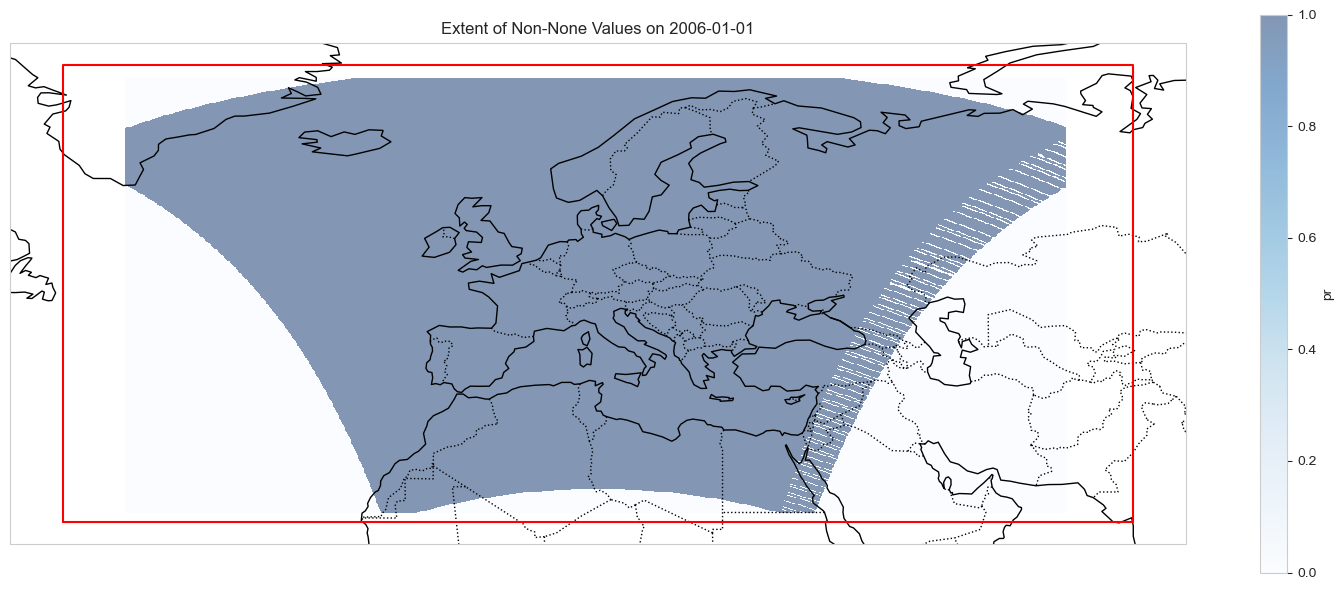

In [21]:
# Select the timestep 2006-01-01 for ds_pr_2006 and ds_pr
pr_2006 = ds_pr_2006.pr.sel(time="2006-01-01")
pr = ds_pr.ds_data.pr.sel(time="2006-01-01")

# Create masks for non-None values
mask_pr_2006 = ~pr_2006.isnull()
mask_pr = ~pr.isnull()

# # Create a figure with two subplots
fig, axes = plt.subplots(
    1, 1, subplot_kw={"projection": ccrs.PlateCarree()}, figsize=(15, 6)
)

pr_2006_lon = np.linspace(
        ds_pr_2006.bounds_lon.min(), ds_pr_2006.bounds_lon.max(), pr_2006.sizes["x"]
    )
pr_2006_lat = np.linspace(
        ds_pr_2006.bounds_lat.min(), ds_pr_2006.bounds_lat.max(), pr_2006.sizes["y"]
    )

# Plot the extent for pr_2006
axes.plot(
    [pr_2006_lon.min(), pr_2006_lon.max(), pr_2006_lon.max(), pr_2006_lon.min(), pr_2006_lon.min()],
    [pr_2006_lat.min(), pr_2006_lat.min(), pr_2006_lat.max(), pr_2006_lat.max(), pr_2006_lat.min()],
    color="red",
    transform=ccrs.PlateCarree(),
    label="pr_2006 extent",
)


# # Plot the extent for ds_pr
# axes.contour(
#     pr.lon,
#     pr.lat,
#     mask_pr.isel(time=0),
#     levels=[0.5],
#     colors="blue",
#     transform=ccrs.PlateCarree(),
# )

mask_pr.plot(ax=axes, transform=ccrs.PlateCarree(), cmap="Blues", alpha=0.5)

axes.set_title("Extent of Non-None Values on 2006-01-01")
axes.coastlines()
axes.add_feature(cfeature.BORDERS, linestyle=":")

plt.tight_layout()
plt.show()